# Regression Activation Maps (RAMs)

**RAMs** — an error-based, gradient-weighted attribution metric adapted to continuous
parameter regression — turning the networks into traceable gray-box models. Produces per-layer
and per-parameter activation maps, spatial overlays on the input textures, and layer×parameter
heatmaps revealing the hierarchical physical decoupling learned by the network.


In [1]:
!pip install tensorflow scikit-learn pandas matplotlib scipy --quiet
print("✅ Librerías instaladas.")

✅ Librerías instaladas.


In [2]:
import os, gc, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
import tensorflow as tf
from scipy.ndimage import zoom
    
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
   
warnings.filterwarnings('ignore')
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE; FS_LABEL = 11 * FONTSCALE
FS_TICK = 10 * FONTSCALE; FS_STATS = 9 * FONTSCALE
c_line = "#1a5276"

OUT_DIR = "/workspace/Process/Images"
os.makedirs(OUT_DIR, exist_ok=True)

param_names = ["T", "Jex2", "Jex3", "Jex4", "Kan1", "KanS", "Hex", "KDM"]
VARIABLES = {
    r"$T^{(0)}$": 0, r"$\tilde{J}_2$": 1, r"$\tilde{J}_3$": 2, r"$\tilde{J}_4$": 3,
    r"$\tilde{K}_{an1}$": 4, r"$\tilde{K}_{anS}$": 5, r"$\tilde{H}_{ex}$": 6, r"$\tilde{K}_{DM}$": 7,
}
var_names = list(VARIABLES.keys())
N_PARAMS = 8
GAMMA = 10.0

print(f"TF: {tf.__version__}")

2026-07-16 19:11:30.141682: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-07-16 19:11:30.214702: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-07-16 19:11:31.717571: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TF: 2.20.0


In [3]:
DATASET_PATH = "/workspace/Preprocess/latent_space_outputs/dataset_final_estructuras.npz"

data = np.load(DATASET_PATH, allow_pickle=True)
X = np.copy(data['img']).astype(np.float32)
y = np.copy(data['params']).astype(np.float32)
label_all = np.array([str(s) for s in data['label_names']])
   
# Split idéntico + recuperar etiquetas de test
idx_all = np.arange(len(X))
X_train, X_test, y_train, y_test, idx_tr, idx_te = train_test_split(
    X, y, idx_all, test_size=0.15, random_state=SEED)
label_test = label_all[idx_te]

scaler = MinMaxScaler().fit(
    train_test_split(y_train, test_size=0.1765, random_state=SEED)[0])
y_test_scaled = scaler.transform(y_test)

print(f"Test: {X_test.shape[0]:,} | estructuras: {np.unique(label_test)}")

Test: 24,922 | estructuras: ['Bimerones' 'Ising' 'Others' 'Skyrmiones' 'helical']


In [4]:
BASE = "/workspace/Models/Inverse/ModelWeights"
# Ajusta el nombre al Xception que quieras interpretar (el mejor sin hetero):
MODEL_PATH = f"{BASE}/modelo_xception_aug_scratch_noweights_estructuras.keras"

class PhysicalAugmentation(tf.keras.layers.Layer):
    def call(self, x, training=None): return x
    def get_config(self): return super().get_config()
    
model = tf.keras.models.load_model(
    MODEL_PATH, compile=False,
    custom_objects={"PhysicalAugmentation": PhysicalAugmentation})
print(f"✅ Modelo cargado | input: {model.input_shape}")

# El backbone Xception está anidado. Localizarlo:
xception_backbone = None
for layer in model.layers:
    if isinstance(layer, tf.keras.Model) and 'xception' in layer.name.lower():
        xception_backbone = layer
        break
if xception_backbone is None:
    for layer in model.layers:
        if isinstance(layer, tf.keras.Model):
            xception_backbone = layer; break

print(f"Backbone: {xception_backbone.name}")
print("\nCapas sepconv disponibles:")
sep_layers = [l.name for l in xception_backbone.layers if 'sepconv' in l.name]
print(sep_layers)

I0000 00:00:1784229117.757624    7564 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 123681 MB memory:  -> device: 0, name: NVIDIA H200, pci bus id: 0000:ba:00.0, compute capability: 9.0


✅ Modelo cargado | input: (None, 39, 39, 1)
Backbone: xception

Capas sepconv disponibles:
['block2_sepconv1', 'block2_sepconv1_bn', 'block2_sepconv2_act', 'block2_sepconv2', 'block2_sepconv2_bn', 'block3_sepconv1_act', 'block3_sepconv1', 'block3_sepconv1_bn', 'block3_sepconv2_act', 'block3_sepconv2', 'block3_sepconv2_bn', 'block4_sepconv1_act', 'block4_sepconv1', 'block4_sepconv1_bn', 'block4_sepconv2_act', 'block4_sepconv2', 'block4_sepconv2_bn', 'block5_sepconv1_act', 'block5_sepconv1', 'block5_sepconv1_bn', 'block5_sepconv2_act', 'block5_sepconv2', 'block5_sepconv2_bn', 'block5_sepconv3_act', 'block5_sepconv3', 'block5_sepconv3_bn', 'block6_sepconv1_act', 'block6_sepconv1', 'block6_sepconv1_bn', 'block6_sepconv2_act', 'block6_sepconv2', 'block6_sepconv2_bn', 'block6_sepconv3_act', 'block6_sepconv3', 'block6_sepconv3_bn', 'block7_sepconv1_act', 'block7_sepconv1', 'block7_sepconv1_bn', 'block7_sepconv2_act', 'block7_sepconv2', 'block7_sepconv2_bn', 'block7_sepconv3_act', 'block7_sepc

In [5]:
LAYER_NAMES = [
    "block1_conv2", "block3_sepconv2", "block4_sepconv2", "block6_sepconv2",
    "block8_sepconv2", "block10_sepconv2", "block12_sepconv2", "block13_sepconv2",
]
avail = set(l.name for l in xception_backbone.layers)
LAYER_NAMES = [ln for ln in LAYER_NAMES if ln in avail]
print("Capas usadas:", LAYER_NAMES)

TARGET_H = TARGET_W = 224



def build_grad_model(layer_name):
    """grad_model desde la ENTRADA DEL BACKBONE (224×224×3) a [activación interna, salida params].
    Reaplica la cabeza del modelo (todo lo que va después del backbone)."""
    conv_feat = xception_backbone.get_layer(layer_name).output
    x = xception_backbone.output
    head_started = False
    for layer in model.layers:
        if layer is xception_backbone:
            head_started = True
            continue
        if head_started:
            x = layer(x)
    return tf.keras.models.Model(
        inputs=xception_backbone.input,
        outputs=[conv_feat, x])

print("\nConstruyendo grad_models...")
grad_models = {ln: build_grad_model(ln) for ln in LAYER_NAMES}
print(f"✅ {len(grad_models)} grad_models listos")


def preprocess_to_224(img_39):
    """Replica augment(identidad)+resize+RGB del modelo: (39,39,1) -> (1,224,224,3)."""
    t = tf.constant(img_39[None, ...], dtype=tf.float32)     # (1,39,39,1)
    t = tf.image.resize(t, [224, 224])                       # (1,224,224,1)
    t = tf.concat([t, t, t], axis=-1)                        # (1,224,224,3)
    return t

def compute_ram(img_224_tensor, gm, y_scaled_val, var_idx, gamma=GAMMA):
    """RAM: O_p=exp(-γε²) → grad-pool → ReLU → upsample. Raw (sin normalizar)."""
    theta_true = tf.constant([[float(y_scaled_val[var_idx])]], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = gm(img_224_tensor, training=False)
        tape.watch(conv_out)
        theta_hat = preds[:, var_idx:var_idx+1]
        objective = tf.exp(-gamma * tf.square(theta_true - theta_hat))
    grads = tape.gradient(objective, conv_out)
    if grads is None:
        return np.zeros((TARGET_H, TARGET_W))
    pooled = tf.reduce_mean(grads, axis=(0, 1, 2)).numpy()
    conv_np = conv_out.numpy()[0]
    for k in range(pooled.shape[-1]):
        conv_np[:, :, k] *= pooled[k]
    hm = np.maximum(np.mean(conv_np, axis=-1), 0)
    h, w = hm.shape
    return zoom(hm, (TARGET_H / h, TARGET_W / w))

print("✅ Funciones RAM listas (espacio 224)")      

Capas usadas: ['block1_conv2', 'block3_sepconv2', 'block4_sepconv2', 'block6_sepconv2', 'block8_sepconv2', 'block10_sepconv2', 'block12_sepconv2', 'block13_sepconv2']

Construyendo grad_models...
✅ 8 grad_models listos
✅ Funciones RAM listas (espacio 224)


In [6]:
structures = ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
structures = [s for s in structures if (label_test == s).sum() > 0]
   

structure_colors = {
    "helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4",
}
structure_labels = {
    "helical": "Helical phase", "Others": "Others", "Bimerones": "Bimerons",
    "Skyrmiones": "Skyrmions", "Ising": "Ising phase",
}

# Representante = el más cercano a la media de parámetros de su estructura
single_rep = {}
for s in structures:
    idx = np.where(label_test == s)[0]
    mean_p = y_test[idx].mean(axis=0)
    best_local = np.argmin(np.linalg.norm(y_test[idx] - mean_p, axis=1))
    single_rep[s] = idx[best_local]

print("Representantes:")
for s, i in single_rep.items():
    print(f"  {s:<12} → idx={i} | T={y_test[i,0]:.2f} | KDM={y_test[i,7]:.3f}")

Representantes:
  helical      → idx=6428 | T=4.10 | KDM=0.760
  Others       → idx=21854 | T=4.70 | KDM=0.000
  Bimerones    → idx=15235 | T=4.10 | KDM=0.000
  Skyrmiones   → idx=8187 | T=3.80 | KDM=0.975
  Ising        → idx=9454 | T=2.00 | KDM=0.497


In [7]:
import numpy as np
import tensorflow as tf
from scipy.ndimage import zoom

    

VARIABLES_PAPER = {
    r"$T^{(0)}$":        0,
    r"$\tilde{J}_2$":    1,
    r"$\tilde{K}_{DM}$": 7,
}
      
LAYER_NAMES = [
    "block1_conv2", "block3_sepconv2", "block4_sepconv2", "block6_sepconv2",
    "block8_sepconv2", "block10_sepconv2", "block12_sepconv2", "block13_sepconv2",
]
layer_short_paper = ["B1", "B3", "B4", "B6", "B8", "B10", "B12", "B13"]

structures = ["helical", "Others", "Bimerones", "Skyrmiones", "Ising"]
structures = [s for s in structures if (label_test == s).sum() > 0]

structure_colors = {
    "helical": "#d62728", "Others": "#ff7f0e", "Bimerones": "#9467bd",
    "Skyrmiones": "#2ca02c", "Ising": "#1f77b4",
}
structure_labels = {
    "helical": "Helical phase", "Others": "Others", "Bimerones": "Bimerons",
    "Skyrmiones": "Skyrmions", "Ising": "Ising phase",
}

TARGET_H = TARGET_W = 224
GAMMA = 10.0

def make_circular_mask(size=224, margin=0.06):
    cy = cx = size // 2
    r = (size // 2) * (1 - margin)
    Y, X_ = np.ogrid[:size, :size]
    return ((X_ - cx)**2 + (Y - cy)**2) <= r**2

def mask_ram(heatmap, mask):
    h = heatmap.copy(); h[~mask] = 0.0; return h

def concentration_score(heatmap, mask):
    total = heatmap.sum() + 1e-10
    return (heatmap * mask).sum() / total

circ_mask = make_circular_mask(224, margin=0.06)

# RAM (float32, entrada 224)
def compute_ram_cnn(img_224_tensor, gm, y_scaled_val, var_idx, gamma=GAMMA):
    theta_true = tf.constant([[float(y_scaled_val[var_idx])]], dtype=tf.float32)
    with tf.GradientTape() as tape:
        conv_out, preds = gm(img_224_tensor, training=False)
        tape.watch(conv_out)
        theta_hat = preds[:, var_idx:var_idx+1]
        objective = tf.exp(-gamma * tf.square(theta_true - tf.cast(theta_hat, tf.float32)))
    grads = tape.gradient(objective, conv_out)
    if grads is None:
        return np.zeros((TARGET_H, TARGET_W), dtype=np.float32)
    pooled  = tf.reduce_mean(tf.cast(grads, tf.float32), axis=(0, 1, 2)).numpy()
    conv_np = tf.cast(conv_out, tf.float32).numpy()[0]
    for k in range(pooled.shape[-1]):
        conv_np[:, :, k] *= pooled[k]
    hm = np.maximum(np.mean(conv_np, axis=-1), 0).astype(np.float32)
    h, w = hm.shape
    return zoom(hm, (TARGET_H / h, TARGET_W / w))

# ── Mejor representante: mayor score de concentración entre los 10 más cercanos a la media ──
print("Seleccionando mejor representante por estructura...")
best_rep = {}
for s in structures:
    idx_all = np.where(label_test == s)[0]
    mean_p  = y_test[idx_all].mean(axis=0)
    top10   = idx_all[np.argsort(np.linalg.norm(y_test[idx_all] - mean_p, axis=1))[:10]]
   
    best_score, best_idx = -1, top10[0]
    for cand in top10:
        img_arr = preprocess_to_224(X_test[cand])
        y_sc    = y_test_scaled[cand]
        scores = []
        for ln in LAYER_NAMES:
            for vn, vi in VARIABLES_PAPER.items():
                r = compute_ram_cnn(img_arr, grad_models[ln], y_sc, vi)
                scores.append(concentration_score(mask_ram(r, circ_mask), circ_mask))
        ms = np.mean(scores)
        if ms > best_score:
            best_score, best_idx = ms, cand
    best_rep[s] = best_idx
    print(f"  {s:<12} → idx={best_idx} | score={best_score:.3f} | "
          f"T={y_test[best_idx,0]:.2f} | KDM={y_test[best_idx,7]:.3f}")

Seleccionando mejor representante por estructura...


2026-07-16 19:12:11.755615: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91002


  helical      → idx=669 | score=1.001 | T=4.10 | KDM=0.779
  Others       → idx=19970 | score=1.000 | T=4.80 | KDM=0.000
  Bimerones    → idx=18913 | score=1.004 | T=4.10 | KDM=0.000
  Skyrmiones   → idx=11944 | score=3.463 | T=3.60 | KDM=0.840
  Ising        → idx=12589 | score=1.004 | T=1.50 | KDM=0.731


In [8]:
print("Calculando RAMs del mejor representante...")
rams_best = {}
for s, sidx in best_rep.items():
    img_arr = preprocess_to_224(X_test[sidx])
    y_sc    = y_test_scaled[sidx]
    rams_best[s] = {"idx": sidx, "img": X_test[sidx][:, :, 0],
                    "y_val": y_test[sidx], "rams": {}}
    for ln in LAYER_NAMES:
        rams_best[s]["rams"][ln] = {}
        for vn, vi in VARIABLES_PAPER.items():
            r = compute_ram_cnn(img_arr, grad_models[ln], y_sc, vi)
            rams_best[s]["rams"][ln][vn] = mask_ram(r, circ_mask)
    print(f"  ✓ {s}")
print("\n✅ rams_best listo")

Calculando RAMs del mejor representante...
  ✓ helical
  ✓ Others
  ✓ Bimerones
  ✓ Skyrmiones
  ✓ Ising

✅ rams_best listo


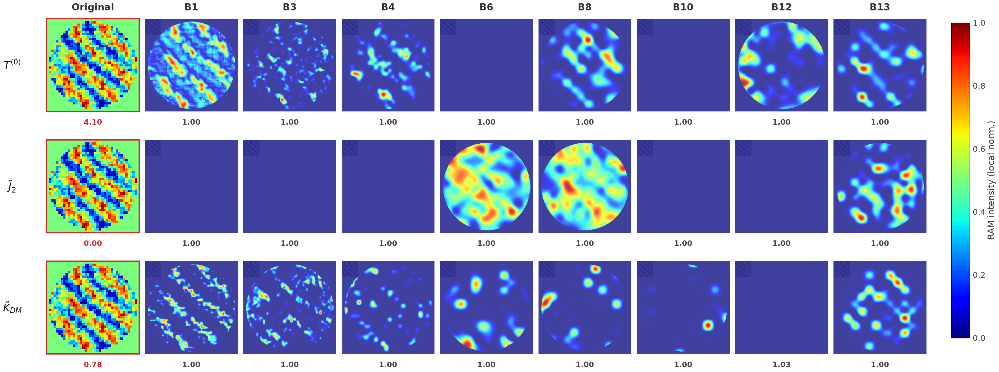

✅ rams_xception_overlay_helical.pdf


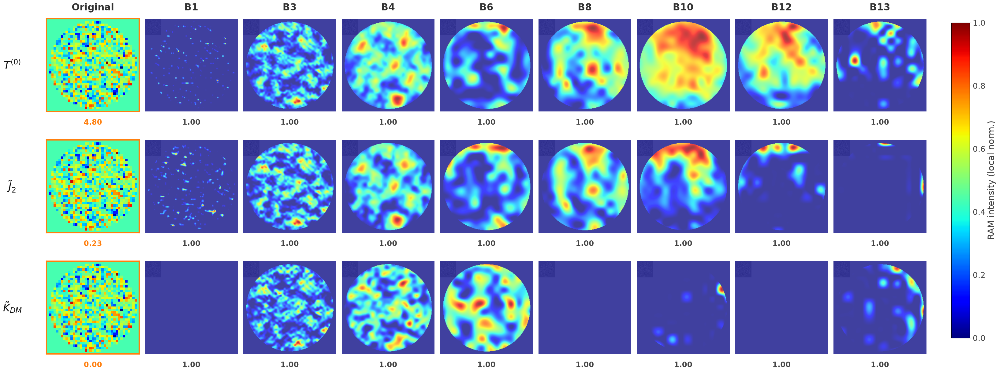

✅ rams_xception_overlay_Others.pdf


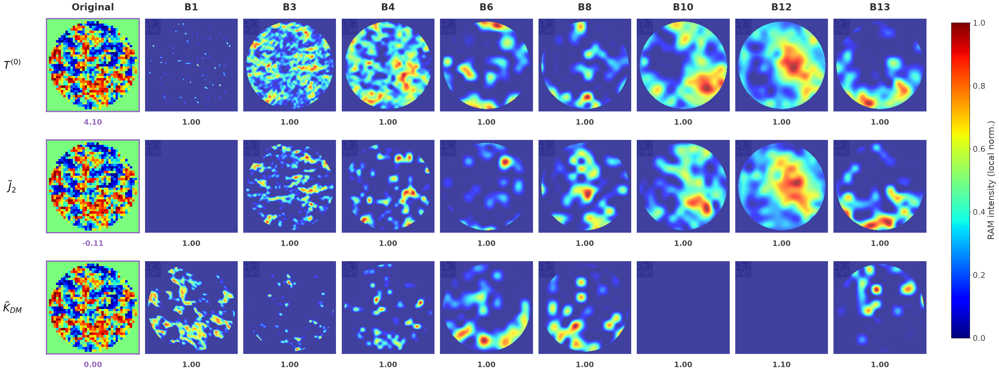

✅ rams_xception_overlay_Bimerones.pdf


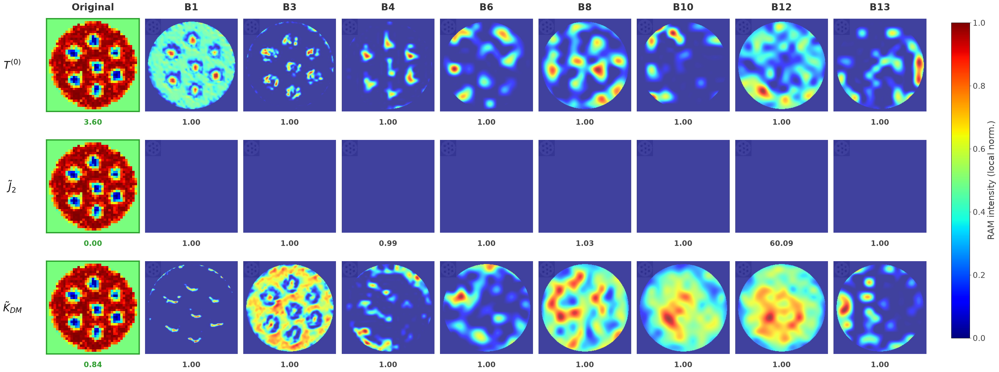

✅ rams_xception_overlay_Skyrmiones.pdf


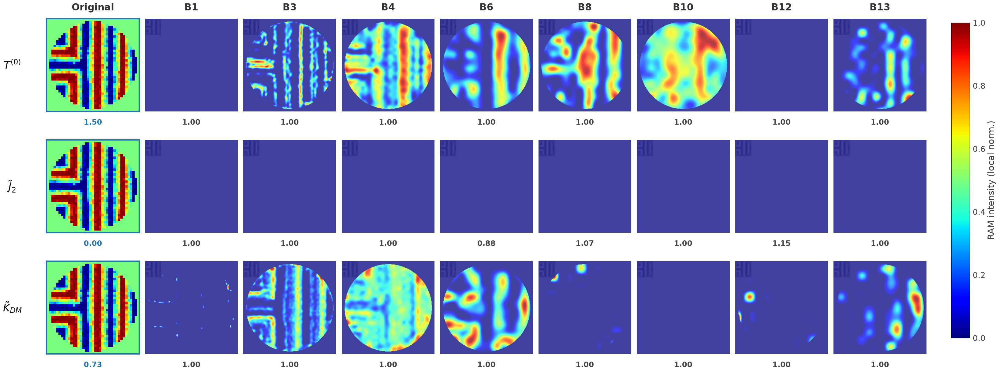

✅ rams_xception_overlay_Ising.pdf


In [9]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
  
FONTSCALE = 2.2
FS_LABEL = 11 * FONTSCALE; FS_TICK = 10 * FONTSCALE; FS_STATS = 8 * FONTSCALE
NDEC = 2

n_vars_p = len(VARIABLES_PAPER)
n_layers = len(LAYER_NAMES)
n_cols   = n_layers + 1

# ── UNA FIGURA POR CADA ESTRUCTURA ──
for s in structures:
    if s not in rams_best:
        print(f"⚠ {s} no está en rams_best, la salto")
        continue

    color = structure_colors[s]; label = structure_labels[s]
    data  = rams_best[s]; img = data["img"]; y_vals = data["y_val"]
    imin, imax = img.min(), img.max()

    n_rows = n_vars_p   # 3 variables
    fig = plt.figure(figsize=(4.5 * n_cols, 4.4 * n_rows), facecolor="white")
    gs = gridspec.GridSpec(n_rows, n_cols, figure=fig, hspace=0.20, wspace=0.06,
                           left=0.16, right=0.87, top=0.90, bottom=0.05)

    # Encabezados de columna
    col_labels_all = ["Original"] + layer_short_paper
    for j, lbl in enumerate(col_labels_all):
        ax_tmp = fig.add_subplot(gs[0, j])
        ax_tmp.set_title(lbl, fontsize=FS_TICK, fontweight="bold", color="#333", pad=10)
        ax_tmp.axis("off")

    for v_i, (vn, vi) in enumerate(VARIABLES_PAPER.items()):
        row = v_i

        # Col 0 — imagen original
        ax0 = fig.add_subplot(gs[row, 0])
        ax0.imshow(img, cmap="jet", vmin=imin, vmax=imax, interpolation="nearest")
        ax0.set_xticks([]); ax0.set_yticks([])
        ax0.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
        for sp in ax0.spines.values():
            sp.set_edgecolor(color); sp.set_linewidth(3.0); sp.set_visible(True)
        ax0.set_ylabel(vn, fontsize=FS_LABEL, fontweight="bold", color="#111",
                       rotation=0, labelpad=80, va="center")
        ax0.text(0.5, -0.08, f"{y_vals[vi]:.{NDEC}f}", transform=ax0.transAxes,
                 ha="center", va="top", fontsize=FS_STATS, color=color, fontweight="bold")

        # Col 1..N — RAM local-normalizado + overlay
        for j, ln in enumerate(LAYER_NAMES):
            ax = fig.add_subplot(gs[row, j + 1])
            r_masked = data["rams"][ln][vn]
            r_max = r_masked.max()
            r_local = r_masked / r_max if r_max > 1e-8 else r_masked   # NORM LOCAL

            ax.imshow(img, cmap="gray", vmin=imin, vmax=imax,
                      alpha=0.35, interpolation="nearest")
            ax.imshow(r_local, cmap="jet", vmin=0, vmax=1, alpha=0.75,
                      interpolation="bilinear")
            ax.set_xticks([]); ax.set_yticks([])
            ax.tick_params(left=False, bottom=False, labelleft=False, labelbottom=False)
            for sp in ax.spines.values():
                sp.set_visible(False)

            score = concentration_score(r_masked, circ_mask)
            ax.text(0.5, -0.08, f"{score:.{NDEC}f}", transform=ax.transAxes,
                    ha="center", va="top", fontsize=FS_STATS, fontweight="bold",
                    color="#444444" if score > 0.7 else "#cc4444")

    # Colorbar
    cbar_ax = fig.add_axes([0.89, 0.10, 0.015, 0.78])
    sm = ScalarMappable(cmap="jet", norm=Normalize(vmin=0, vmax=1)); sm.set_array([])
    cb = fig.colorbar(sm, cax=cbar_ax)
    cb.set_label(r"RAM intensity (local norm.)", fontsize=FS_LABEL * 0.85, color="#444444")
    cb.ax.tick_params(labelsize=FS_TICK * 0.85, colors="#444444")

    fname = f"rams_xception_overlay_{s}.pdf"
    plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight", facecolor="white")
    plt.show()
    print(f"✅ {fname}")



    

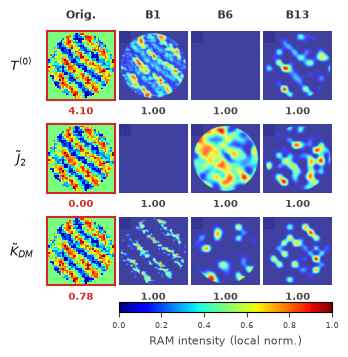

✅ rams_xception_overlay_helical_1col.pdf


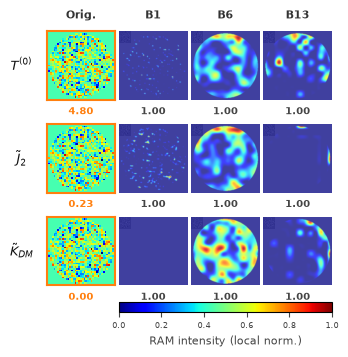

✅ rams_xception_overlay_Others_1col.pdf


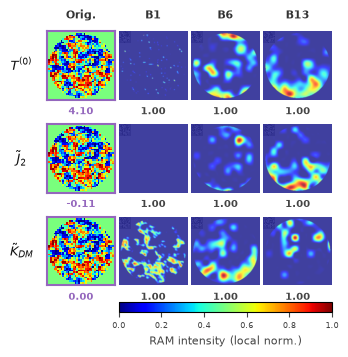

✅ rams_xception_overlay_Bimerones_1col.pdf


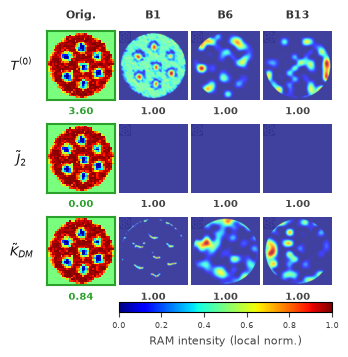

✅ rams_xception_overlay_Skyrmiones_1col.pdf


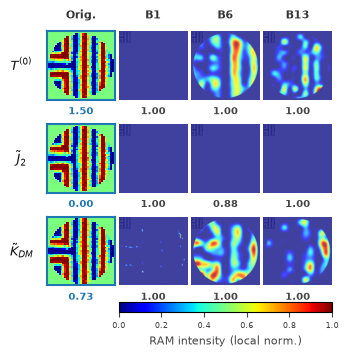

✅ rams_xception_overlay_Ising_1col.pdf


In [12]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

# ── Ancho de columna simple (ajusta a tu plantilla, en pulgadas) ──
COL_WIDTH_IN = 3.4   # típico single-column IEEE/APS/Elsevier

FONTSCALE = 1.0
FS_LABEL = 9 * FONTSCALE
FS_TICK  = 8 * FONTSCALE
FS_STATS = 7 * FONTSCALE
NDEC = 2

# ── Bloques representativos: entrada, medio, salida ──
compact_idx = [0, 3, 7]   # block1_conv2, block6_sepconv2, block13_sepconv2
LAYER_NAMES_COMPACT = [LAYER_NAMES[i] for i in compact_idx]        # claves reales del dict
layer_short_compact = [layer_short_paper[i] for i in compact_idx] # etiquetas cortas

n_vars_p = len(VARIABLES_PAPER)
n_layers = len(LAYER_NAMES_COMPACT)
n_cols   = n_layers + 1   # Original + bloques

for s in structures:
    if s not in rams_best:
        print(f"⚠ {s} no está en rams_best, la salto")
        continue
    color = structure_colors[s]; label = structure_labels[s]
    data  = rams_best[s]; img = data["img"]; y_vals = data["y_val"]
    imin, imax = img.min(), img.max()
    n_rows = n_vars_p

    cell_h = COL_WIDTH_IN / n_cols
    fig_h  = cell_h * n_rows * 1.15 + 0.5
    fig = plt.figure(figsize=(COL_WIDTH_IN, fig_h), facecolor="white")

    gs = gridspec.GridSpec(
        n_rows + 1, n_cols, figure=fig,
        height_ratios=[1]*n_rows + [0.12],
        hspace=0.15, wspace=0.05,
        left=0.14, right=0.98, top=0.90, bottom=0.06
    )

    col_labels_all = ["Orig."] + layer_short_compact
    for j, lbl in enumerate(col_labels_all):
        ax_tmp = fig.add_subplot(gs[0, j])
        ax_tmp.set_title(lbl, fontsize=FS_TICK, fontweight="bold", color="#333", pad=4)
        ax_tmp.axis("off")

    for v_i, (vn, vi) in enumerate(VARIABLES_PAPER.items()):
        row = v_i
        ax0 = fig.add_subplot(gs[row, 0])
        ax0.imshow(img, cmap="jet", vmin=imin, vmax=imax, interpolation="nearest")
        ax0.set_xticks([]); ax0.set_yticks([])
        for sp in ax0.spines.values():
            sp.set_edgecolor(color); sp.set_linewidth(1.5); sp.set_visible(True)
        ax0.set_ylabel(vn, fontsize=FS_LABEL, fontweight="bold", color="#111",
                        rotation=0, labelpad=18, va="center")
        ax0.text(0.5, -0.10, f"{y_vals[vi]:.{NDEC}f}", transform=ax0.transAxes,
                  ha="center", va="top", fontsize=FS_STATS, color=color, fontweight="bold")

        for j, ln in enumerate(LAYER_NAMES_COMPACT):
            ax = fig.add_subplot(gs[row, j + 1])
            r_masked = data["rams"][ln][vn]
            r_max = r_masked.max()
            r_local = r_masked / r_max if r_max > 1e-8 else r_masked
            ax.imshow(img, cmap="gray", vmin=imin, vmax=imax, alpha=0.35, interpolation="nearest")
            ax.imshow(r_local, cmap="jet", vmin=0, vmax=1, alpha=0.75, interpolation="bilinear")
            ax.set_xticks([]); ax.set_yticks([])
            for sp in ax.spines.values():
                sp.set_visible(False)
            score = concentration_score(r_masked, circ_mask)
            ax.text(0.5, -0.10, f"{score:.{NDEC}f}", transform=ax.transAxes,
                    ha="center", va="top", fontsize=FS_STATS, fontweight="bold",
                    color="#444444" if score > 0.7 else "#cc4444")

    cbar_ax = fig.add_subplot(gs[n_rows, 1:])
    sm = ScalarMappable(cmap="jet", norm=Normalize(vmin=0, vmax=1)); sm.set_array([])
    cb = fig.colorbar(sm, cax=cbar_ax, orientation="horizontal")
    cb.set_label("RAM intensity (local norm.)", fontsize=FS_LABEL * 0.85, color="#444444")
    cb.ax.tick_params(labelsize=FS_TICK * 0.7, colors="#444444")

    fname = f"rams_xception_overlay_{s}_1col.pdf"
    plt.savefig(f"{OUT_DIR}/{fname}", bbox_inches="tight", facecolor="white", dpi=300)
    plt.show()
    print(f"✅ {fname}")

Error medio (escala normalizada) por parámetro:
  T     : 0.0166
  Jex2  : 0.0178
  Jex3  : 0.0467
  Jex4  : 0.0455
  Kan1  : 0.0113
  KanS  : 0.1358
  Hex   : 0.0105
  KDM   : 0.0163


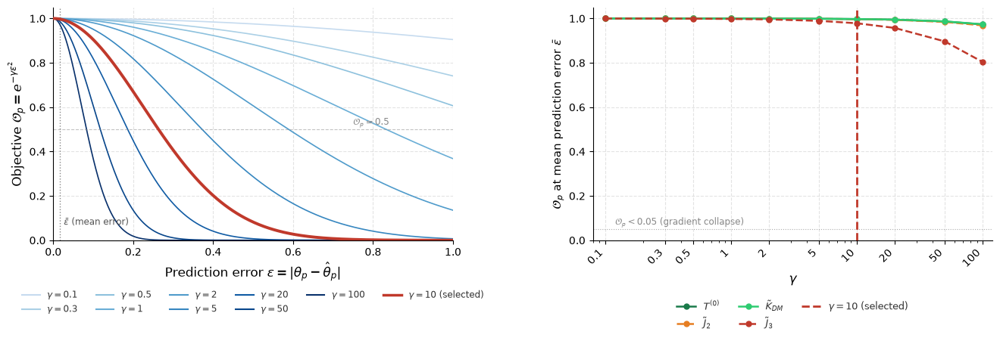

✅ gamma_gaussian_shape.pdf


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

# ── 1) Error medio real (escala normalizada) del Xception, por parámetro ──
n_sub = min(3000, len(X_test))
rng = np.random.default_rng(42)
sub = rng.choice(len(X_test), n_sub, replace=False)

preds_scaled = []
for i in sub:
    _, p = grad_models[LAYER_NAMES[0]](preprocess_to_224(X_test[i]), training=False)
    preds_scaled.append(p.numpy()[0])
preds_scaled = np.array(preds_scaled)

mean_err_scaled = np.abs(y_test_scaled[sub] - preds_scaled).mean(axis=0)
   
print("Error medio (escala normalizada) por parámetro:")
for i, name in enumerate(param_names):
    print(f"  {name:6s}: {mean_err_scaled[i]:.4f}")

mean_errors = {
    r"$T^{(0)}$":        float(mean_err_scaled[0]),
    r"$\tilde{J}_2$":    float(mean_err_scaled[1]),
    r"$\tilde{K}_{DM}$": float(mean_err_scaled[7]),
    r"$\tilde{J}_3$":    float(mean_err_scaled[2]),
}

# ── 2) Figura de dos paneles ──
GAMMAS_PLOT = [0.1, 0.3, 0.5, 1, 2, 5, 10, 20, 50, 100]
cmap = plt.cm.Blues
colors = [cmap(0.25 + 0.75 * i / (len(GAMMAS_PLOT) - 1)) for i in range(len(GAMMAS_PLOT))]
epsilon = np.linspace(0, 1, 500)
gammas_arr = np.array(GAMMAS_PLOT, dtype=float)

var_colors_plot = {
    r"$T^{(0)}$": "#1a7a4a", r"$\tilde{K}_{DM}$": "#2ecc71",
    r"$\tilde{J}_2$": "#e67e22", r"$\tilde{J}_3$": "#c0392b",
}

fig, axes = plt.subplots(1, 2, figsize=(16, 4), facecolor="white",
                         gridspec_kw={"wspace": 0.35})

# Panel izquierdo: forma de la gaussiana por γ
ax = axes[0]
for gamma, color in zip(GAMMAS_PLOT, colors):
    ax.plot(epsilon, np.exp(-gamma * epsilon**2), color=color, linewidth=1.2, zorder=2)
ax.plot(epsilon, np.exp(-10 * epsilon**2), color="#c0392b", linewidth=2.8, zorder=5)

err_typ = np.mean([mean_errors[r"$T^{(0)}$"], mean_errors[r"$\tilde{K}_{DM}$"]])
ax.axvline(err_typ, color="#555", linewidth=1.0, linestyle=":", alpha=0.7)
ax.text(err_typ + 0.01, 0.06, r"$\bar{\varepsilon}$ (mean error)",
        fontsize=8.5, color="#555", va="bottom")
ax.axhline(0.5, color="#888", linewidth=0.8, linestyle="--", alpha=0.5)
ax.text(0.75, 0.52, r"$\mathcal{O}_p = 0.5$", fontsize=8.5, color="#888")

ax.set_xlabel(r"Prediction error $\varepsilon = |\theta_p - \hat{\theta}_p|$", fontsize=12)
ax.set_ylabel(r"Objective $\mathcal{O}_p = e^{-\gamma\varepsilon^2}$", fontsize=12)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.grid(linestyle="--", alpha=0.35)
ax.spines[["top", "right"]].set_visible(False)
legend_handles = [Line2D([0], [0], color=colors[i], linewidth=1.5, label=rf"$\gamma={g}$")
                  for i, g in enumerate(GAMMAS_PLOT) if g != 10] + \
                 [Line2D([0], [0], color="#c0392b", linewidth=2.5, label=r"$\gamma=10$ (selected)")]
ax.legend(handles=legend_handles, loc="upper center", bbox_to_anchor=(0.5, -0.18),
          ncol=6, fontsize=8.5, frameon=False, labelcolor="#333")

# Panel derecho: O_p en el error medio real, por variable
ax2 = axes[1]
for var_name, err_mean in mean_errors.items():
    O_vals = np.exp(-gammas_arr * err_mean**2)
    ls = "-" if ("T" in var_name or "DM" in var_name) else "--"
    ax2.plot(gammas_arr, O_vals, color=var_colors_plot[var_name], linewidth=1.8,
             marker="o", markersize=5, linestyle=ls, zorder=3)
ax2.axvline(10, color="#c0392b", linewidth=2.0, linestyle="--", zorder=4)
ax2.axhline(0.05, color="#888", linewidth=0.8, linestyle=":", alpha=0.7)
ax2.text(0.12, 0.07, r"$\mathcal{O}_p < 0.05$ (gradient collapse)", fontsize=8.5, color="#888")

ax2.set_xscale("log")
ax2.set_xlabel(r"$\gamma$", fontsize=12)
ax2.set_ylabel(r"$\mathcal{O}_p$ at mean prediction error $\bar{\varepsilon}$", fontsize=11)
ax2.set_xlim(0.08, 120); ax2.set_ylim(0, 1.05)
ax2.set_xticks(gammas_arr); ax2.set_xticklabels([str(g) for g in GAMMAS_PLOT], rotation=45, ha="right")
ax2.grid(linestyle="--", alpha=0.35)
ax2.spines[["top", "right"]].set_visible(False)
legend_handles2 = [Line2D([0], [0], color=var_colors_plot[v], linewidth=1.8,
                          linestyle="-" if ("T" in v or "DM" in v) else "--",
                          marker="o", markersize=5, label=v) for v in mean_errors] + \
                  [Line2D([0], [0], color="#c0392b", linewidth=2.0, linestyle="--",
                          label=r"$\gamma=10$ (selected)")]
ax2.legend(handles=legend_handles2, loc="upper center", bbox_to_anchor=(0.5, -0.22),
           ncol=3, fontsize=9, frameon=False, labelcolor="#333")

plt.savefig(f"{OUT_DIR}/gamma_gaussian_shape.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print("✅ gamma_gaussian_shape.pdf")

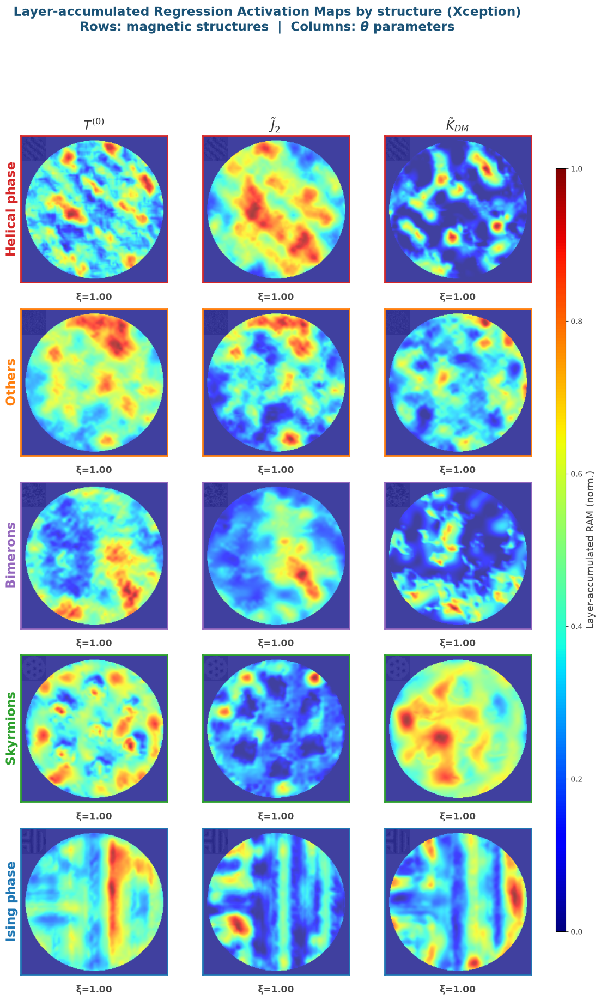

✅ rams_accumulated_by_structure.pdf


In [14]:
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable

FONTSCALE = 1.5
FS_LABEL = 11 * FONTSCALE; FS_STATS = 8 * FONTSCALE
c_line = "#1a5276"

n_vars_p = len(VARIABLES_PAPER)
n_struct = len(structures)

fig, axes = plt.subplots(n_struct, n_vars_p,
                         figsize=(4.2 * n_vars_p, 4.0 * n_struct),
                         facecolor="white",
                         gridspec_kw={"hspace": 0.18, "wspace": 0.08})
if n_struct == 1:
    axes = axes[np.newaxis, :]

for ri, s in enumerate(structures):
    if s not in rams_best:
        continue
    color = structure_colors[s]
    img   = rams_best[s]["img"]
    imin, imax = img.min(), img.max()

    for ci, (vn, vi) in enumerate(VARIABLES_PAPER.items()):
        # sumar RAM sobre todas las capas y normalizar el acumulado
        acc = np.zeros((TARGET_H, TARGET_W), dtype=np.float32)
        for ln in LAYER_NAMES:
            acc += rams_best[s]["rams"][ln][vn]
        amax = acc.max()
        acc = acc / amax if amax > 1e-10 else acc

        ax = axes[ri, ci]
        ax.imshow(img, cmap="gray", vmin=imin, vmax=imax, alpha=0.35, interpolation="nearest")
        ax.imshow(acc, cmap="jet", vmin=0, vmax=1, alpha=0.75, interpolation="bilinear")
        ax.set_xticks([]); ax.set_yticks([])
        for sp in ax.spines.values():
            sp.set_edgecolor(color); sp.set_linewidth(2.0); sp.set_visible(True)

        score = concentration_score(acc, circ_mask)
        ax.text(0.5, -0.07, f"ξ={score:.2f}", transform=ax.transAxes,
                ha="center", va="top", fontsize=FS_STATS, fontweight="bold",
                color="#444444" if score > 0.7 else "#cc4444")

        if ri == 0:
            ax.set_title(vn, fontsize=FS_LABEL, fontweight="bold", color="#333", pad=8)
        if ci == 0:
            ax.set_ylabel(structure_labels[s], fontsize=FS_LABEL, fontweight="bold",
                          color=color, rotation=90, labelpad=12, va="center")

fig.subplots_adjust(right=0.90)
cbar_ax = fig.add_axes([0.92, 0.15, 0.014, 0.70])
sm = ScalarMappable(cmap="jet", norm=Normalize(vmin=0, vmax=1)); sm.set_array([])
cb = fig.colorbar(sm, cax=cbar_ax)
cb.set_label(r"Layer-accumulated RAM (norm.)", fontsize=FS_LABEL * 0.8, color="#444444")
cb.ax.tick_params(labelsize=FS_STATS * 0.85, colors="#444444")

fig.suptitle("Layer-accumulated Regression Activation Maps by structure (Xception)\n"
             r"Rows: magnetic structures  |  Columns: $\boldsymbol{\theta}$ parameters",
             fontsize=FS_LABEL, fontweight="bold", color=c_line, y=1.0)
plt.savefig(f"{OUT_DIR}/rams_accumulated_by_structure.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print("✅ rams_accumulated_by_structure.pdf")


 

In [15]:
!pip install tqdm --quiet
print("✅ tqdm instalado")

✅ tqdm instalado


Índices por estructura...
  helical      → N=18136
  Others       → N=3809
  Bimerones    → N=944
  Skyrmiones   → N=1822
  Ising        → N=211

──────────────────────────────────────────────────
  helical  (N=300)
──────────────────────────────────────────────────


helical     :   0%|                              | 0/64 [00:00<?, ?it/s]

  ✅ helical — 204.2s

──────────────────────────────────────────────────
  Others  (N=300)
──────────────────────────────────────────────────


Others      :   0%|                              | 0/64 [00:00<?, ?it/s]

  ✅ Others — 232.0s

──────────────────────────────────────────────────
  Bimerones  (N=300)
──────────────────────────────────────────────────


...

  ✅ Bimerones — 257.3s

──────────────────────────────────────────────────
  Skyrmiones  (N=300)
──────────────────────────────────────────────────


Skyrmiones  :   0%|                              | 0/64 [00:00<?, ?it/s]

  ✅ Skyrmiones — 281.8s

──────────────────────────────────────────────────
  Ising  (N=211)
──────────────────────────────────────────────────


Ising       :   0%|                              | 0/64 [00:00<?, ?it/s]

  ✅ Ising — 435.1s

✅ Total: 435.1s


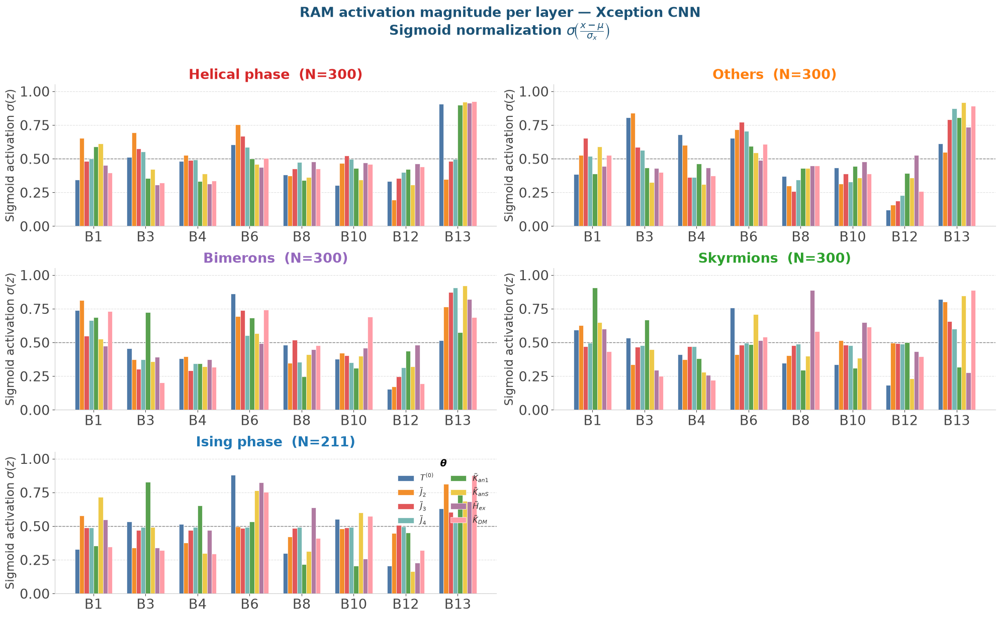

✅ rams_xception_magnitude_bars.pdf


In [16]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
import time
import tensorflow as tf

FONTSCALE = 1.5
FS_TITLE = 13 * FONTSCALE; FS_LABEL = 11 * FONTSCALE
FS_TICK = 13 * FONTSCALE; FS_LEGEND = 9 * FONTSCALE
c_line = "#1a5276"

LAYER_NAMES_NEW = LAYER_NAMES          # las 8 que ya tienes
layer_labels_bar = ["B1", "B3", "B4", "B6", "B8", "B10", "B12", "B13"]

VARIABLES_ALL = {
    r"$T^{(0)}$": 0, r"$\tilde{J}_2$": 1, r"$\tilde{J}_3$": 2, r"$\tilde{J}_4$": 3,
    r"$\tilde{K}_{an1}$": 4, r"$\tilde{K}_{anS}$": 5, r"$\tilde{H}_{ex}$": 6, r"$\tilde{K}_{DM}$": 7,
}
VAR_COLORS_BAR = {
    r"$T^{(0)}$": "#4e79a7", r"$\tilde{J}_2$": "#f28e2b", r"$\tilde{J}_3$": "#e15759",
    r"$\tilde{J}_4$": "#76b7b2", r"$\tilde{K}_{an1}$": "#59a14f", r"$\tilde{K}_{anS}$": "#edc948",
    r"$\tilde{H}_{ex}$": "#b07aa1", r"$\tilde{K}_{DM}$": "#ff9da7",
}

var_names_all = list(VARIABLES_ALL.keys())
n_vars_all = len(var_names_all)
n_layers_new = len(LAYER_NAMES_NEW)

MAX_PER_PHASE  = 300
BATCH_SIZE_RAM = 16
GAMMA = 10.0

# ── Índices por estructura (usando label_test del dataset) ──
print("Índices por estructura...")
phase_indices_new = {}
for s in structures:
    idx = np.where(label_test == s)[0]
    phase_indices_new[s] = idx.tolist()
    print(f"  {s:<12} → N={len(idx)}")

# ── Función RAM batch: devuelve el máximo del heatmap por muestra (magnitud de activación) ──
@tf.function
def compute_ram_batch_max(img_batch, grad_model, y_scaled_batch, var_idx, gamma=GAMMA):
    theta_true = tf.cast(y_scaled_batch[:, var_idx:var_idx+1], tf.float32)
    with tf.GradientTape() as tape:
        conv_output, predictions = grad_model(img_batch, training=False)
        theta_hat = predictions[:, var_idx:var_idx+1]
        objective = tf.reduce_mean(
            tf.exp(-gamma * tf.square(theta_true - tf.cast(theta_hat, tf.float32))))
    grads = tape.gradient(objective, conv_output)
    grads = tf.cast(grads, tf.float32)
    conv_output = tf.cast(conv_output, tf.float32)
    pooled = tf.reduce_mean(grads, axis=(1, 2))
    weighted = conv_output * pooled[:, tf.newaxis, tf.newaxis, :]
    heatmap = tf.nn.relu(tf.reduce_mean(weighted, axis=-1))
    max_vals = tf.reduce_max(tf.reshape(heatmap, (tf.shape(heatmap)[0], -1)), axis=1)
    return max_vals

# ── Preprocesar a 224 un batch de imágenes nativas 39×39 ──
def prep_batch_224(imgs_39):
    t = tf.constant(imgs_39, dtype=tf.float32)          # (n,39,39,1)
    t = tf.image.resize(t, [224, 224])                  # (n,224,224,1)
    t = tf.concat([t, t, t], axis=-1)                   # (n,224,224,3)
    return t

# ── Acumular la magnitud media por estructura × variable × capa ──
accum  = {s: {v: np.zeros(n_layers_new) for v in var_names_all} for s in structures}
counts = {s: 0 for s in structures}

t0 = time.time()
for s in structures:
    all_idxs = phase_indices_new[s][:MAX_PER_PHASE]
    n_total = len(all_idxs)
    counts[s] = n_total
    print(f"\n{'─'*50}\n  {s}  (N={n_total})\n{'─'*50}")

    imgs_phase = np.stack([X_test[i] for i in all_idxs], axis=0).astype(np.float32)  # (n,39,39,1)
    imgs_224   = prep_batch_224(imgs_phase)                                          # (n,224,224,3)
    ys_phase   = y_test_scaled[all_idxs].astype(np.float32)

    pbar = tqdm(total=n_layers_new * n_vars_all, desc=f"{s[:12]:12s}",
                bar_format="{l_bar}{bar:30}{r_bar}", colour="green")

    for l_i, ln in enumerate(LAYER_NAMES_NEW):
        gm = grad_models[ln]
        for v_i, (vn, vi) in enumerate(VARIABLES_ALL.items()):
            batch_maxes = []
            n_batches = int(np.ceil(n_total / BATCH_SIZE_RAM))
            for b in range(n_batches):
                st, en = b * BATCH_SIZE_RAM, min((b+1)*BATCH_SIZE_RAM, n_total)
                mv = compute_ram_batch_max(imgs_224[st:en], gm,
                                           tf.constant(ys_phase[st:en]), vi).numpy()
                batch_maxes.extend(mv.tolist())
            accum[s][vn][l_i] = float(np.mean(batch_maxes))
            pbar.update(1)
            pbar.set_postfix({"layer": ln.replace("block", "B"), "var": vn})
    pbar.close()
    print(f"  ✅ {s} — {time.time()-t0:.1f}s")

print(f"\n✅ Total: {time.time()-t0:.1f}s")

# ── Normalización sigmoid (z-score → sigmoid) ──
def sigmoid_normalize(x):
    x = np.array(x, dtype=np.float64)
    z = (x - x.mean()) / (x.std() + 1e-10)
    return 1 / (1 + np.exp(-z))

accum_norm = {s: {vn: sigmoid_normalize(accum[s][vn]) for vn in var_names_all}
              for s in structures}

# ── Figura: una subplot por estructura, barras por capa×variable ──
x_layers = np.arange(n_layers_new)
bar_w = 0.09
n_struct = len(structures)
ncols = 2
nrows = int(np.ceil(n_struct / ncols))

fig, axes_bar = plt.subplots(nrows, ncols, figsize=(20, 4*nrows), facecolor="white")
axes_bar = np.array(axes_bar).flatten()

for p_i, s in enumerate(structures):
    ax_b = axes_bar[p_i]
    color = structure_colors[s]; label = structure_labels[s]
    for v_i, vn in enumerate(var_names_all):
        offset = (v_i - n_vars_all / 2 + 0.5) * bar_w
        ax_b.bar(x_layers + offset, accum_norm[s][vn], width=bar_w, label=vn,
                 color=VAR_COLORS_BAR[vn], edgecolor="white", linewidth=0.5, zorder=3)
    ax_b.axhline(0.5, color="#555", linewidth=1.0, linestyle="--", alpha=0.7, zorder=2)
    ax_b.set_xticks(x_layers)
    ax_b.set_xticklabels(layer_labels_bar, fontsize=FS_TICK, ha="center")
    ax_b.set_ylabel(r"Sigmoid activation $\sigma(z)$", color="#444444", fontsize=FS_LABEL)
    ax_b.set_title(f"{label}  (N={counts[s]})", fontsize=FS_TITLE, fontweight="bold",
                   color=color, pad=8)
    ax_b.tick_params(colors="#444444", labelsize=FS_TICK)
    ax_b.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
    ax_b.set_ylim(0, 1.05)
    ax_b.spines[["top", "right"]].set_visible(False)
    ax_b.spines["left"].set_color("#cccccc"); ax_b.spines["bottom"].set_color("#cccccc")
    if p_i == n_struct - 1:
        ax_b.legend(title=r"$\boldsymbol{\theta}$", frameon=False, fontsize=FS_LEGEND*0.85,
                    title_fontsize=FS_LEGEND, ncol=2, loc="upper right", labelcolor="#333")

# ocultar ejes sobrantes
for k in range(n_struct, len(axes_bar)):
    axes_bar[k].axis("off")

fig.suptitle("RAM activation magnitude per layer — Xception CNN\n"
             r"Sigmoid normalization $\sigma\!\left(\frac{x-\mu}{\sigma_x}\right)$",
             fontsize=FS_TITLE, fontweight="bold", color=c_line, y=1.02)
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/rams_xception_magnitude_bars.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print("✅ rams_xception_magnitude_bars.pdf")

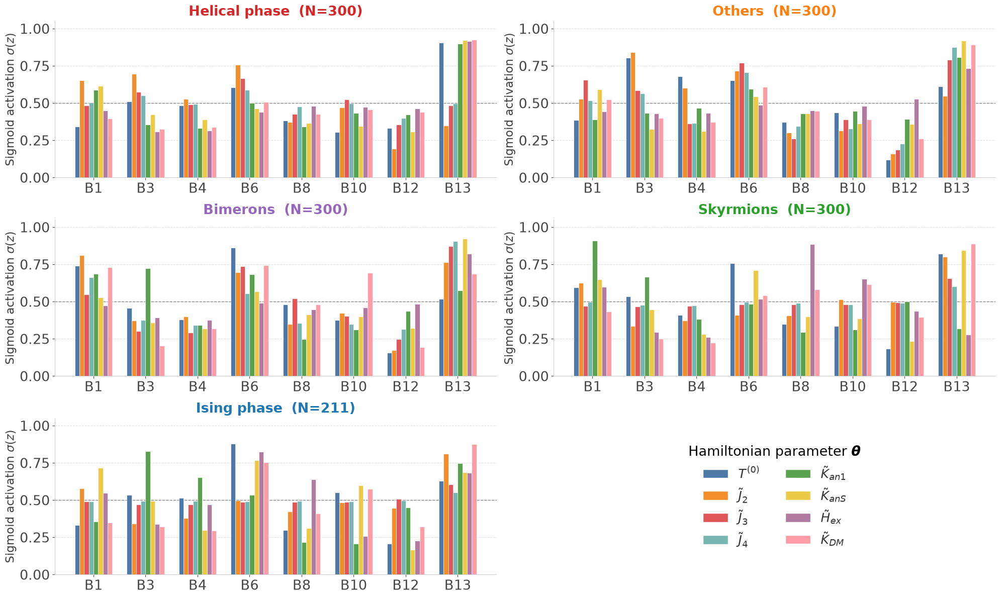

✅ rams_xception_magnitude_bars.pdf


In [17]:
from matplotlib.patches import Patch

x_layers = np.arange(n_layers_new)
bar_w = 0.09
n_struct = len(structures)
ncols = 2
nrows = int(np.ceil((n_struct + 1) / ncols))   # +1 para reservar hueco de leyenda si hace falta

fig, axes_bar = plt.subplots(nrows, ncols, figsize=(20, 4*nrows), facecolor="white")
axes_bar = np.array(axes_bar).flatten()

for p_i, s in enumerate(structures):
    ax_b = axes_bar[p_i]
    color = structure_colors[s]; label = structure_labels[s]
    for v_i, vn in enumerate(var_names_all):
        offset = (v_i - n_vars_all / 2 + 0.5) * bar_w
        ax_b.bar(x_layers + offset, accum_norm[s][vn], width=bar_w, label=vn,
                 color=VAR_COLORS_BAR[vn], edgecolor="white", linewidth=0.5, zorder=3)
    ax_b.axhline(0.5, color="#555", linewidth=1.0, linestyle="--", alpha=0.7, zorder=2)
    ax_b.set_xticks(x_layers)
    ax_b.set_xticklabels(layer_labels_bar, fontsize=FS_TICK, ha="center")
    ax_b.set_ylabel(r"Sigmoid activation $\sigma(z)$", color="#444444", fontsize=FS_LABEL)
    ax_b.set_title(f"{label}  (N={counts[s]})", fontsize=FS_TITLE, fontweight="bold",
                   color=color, pad=8)
    ax_b.tick_params(colors="#444444", labelsize=FS_TICK)
    ax_b.grid(axis="y", linestyle="--", alpha=0.4, zorder=0)
    ax_b.set_ylim(0, 1.05)
    ax_b.spines[["top", "right"]].set_visible(False)
    ax_b.spines["left"].set_color("#cccccc"); ax_b.spines["bottom"].set_color("#cccccc")

# ── Leyenda GRANDE en el hueco sobrante (última celda) ──
legend_ax = axes_bar[n_struct]          # primera celda libre tras las estructuras
legend_ax.axis("off")
legend_handles = [Patch(facecolor=VAR_COLORS_BAR[vn], edgecolor="white", label=vn)
                  for vn in var_names_all]
legend_ax.legend(handles=legend_handles, title=r"Hamiltonian parameter $\boldsymbol{\theta}$",
                 frameon=False, fontsize=FS_LABEL * 1.1, title_fontsize=FS_TITLE,
                 ncol=2, loc="center", labelcolor="#333")

# ocultar cualquier celda extra restante
for k in range(n_struct + 1, len(axes_bar)):
    axes_bar[k].axis("off")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/rams_xception_magnitude_bars.pdf", bbox_inches="tight", facecolor="white")
plt.show()
print("✅ rams_xception_magnitude_bars.pdf")

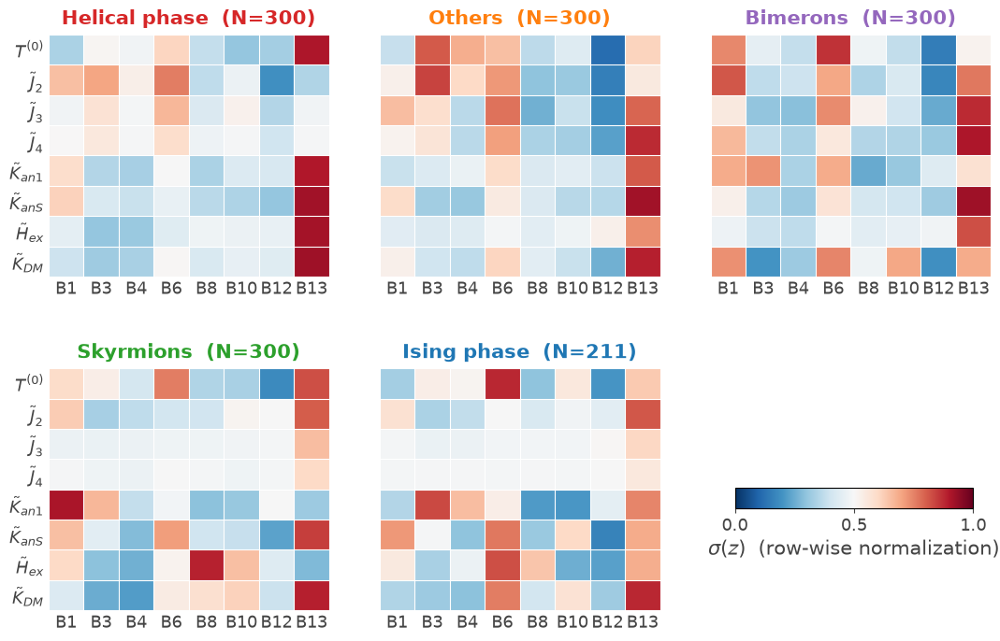

✅ rams_xception_heatmap_grid.pdf


In [19]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ── Matriz por estructura: (n_vars, n_layers) ──
M = {s: np.stack([accum_norm[s][vn] for vn in var_names_all], axis=0) for s in structures}

n_struct = len(structures)
nrows_h, ncols_h = 2, 3

FS_TICK_H = 13; FS_LABEL_H = 15; FS_TITLE_H = 15

fig, axes = plt.subplots(nrows_h, ncols_h, figsize=(13, 8), facecolor="white",
                         gridspec_kw={"wspace": 0.18, "hspace": 0.38})
axes = np.array(axes).flatten()
norm = TwoSlopeNorm(vmin=0.0, vcenter=0.5, vmax=1.0)

for p_i, s in enumerate(structures):
    ax = axes[p_i]
    im = ax.imshow(M[s], cmap="RdBu_r", norm=norm, aspect="auto", interpolation="nearest")

    ax.set_xticks(np.arange(n_layers_new))
    ax.set_xticklabels(layer_labels_bar, fontsize=FS_TICK_H)
    ax.set_yticks(np.arange(n_vars_all))
    # etiquetas de variables solo en la primera columna de cada fila
    if p_i % ncols_h == 0:
        ax.set_yticklabels(var_names_all, fontsize=FS_TICK_H)
    else:
        ax.set_yticklabels([])

    ax.set_title(f"{structure_labels[s]}  (N={counts[s]})", fontsize=FS_TITLE_H,
                 fontweight="bold", color=structure_colors[s], pad=8)
    ax.tick_params(colors="#444444", length=0)

    # rejilla fina entre celdas
    ax.set_xticks(np.arange(-.5, n_layers_new, 1), minor=True)
    ax.set_yticks(np.arange(-.5, n_vars_all, 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=0.8)
    ax.tick_params(which="minor", length=0)
    for sp in ax.spines.values():
        sp.set_visible(False)

# ── Celdas sobrantes: apagar y usar la última para la colorbar ──
for k in range(n_struct, len(axes)):
    axes[k].axis("off")

spare = axes[n_struct]                      # primera celda libre (índice 5 en 2×3)
pos = spare.get_position()
cbar_ax = fig.add_axes([pos.x0 + 0.02, pos.y0 + 0.42 * pos.height,
                        pos.width * 0.85, 0.028])
cb = fig.colorbar(im, cax=cbar_ax, orientation="horizontal", ticks=[0.0, 0.5, 1.0])
cb.set_label(r"$\sigma(z)$  (row-wise normalization)", fontsize=FS_LABEL_H, color="#444")
cb.ax.tick_params(labelsize=FS_TICK_H, colors="#444")

plt.savefig(f"{OUT_DIR}/rams_xception_heatmap_grid.pdf",
            bbox_inches="tight", facecolor="white", dpi=300)
plt.show()
print("✅ rams_xception_heatmap_grid.pdf")